Their workflow for the main dataset is like this:
- `OGBG-MolPCBA_inspecting.ipynb`
    - download the ogbg-molpcba dataset (a dataset of 427,929 molecules)
    - use only the molecule with the highest number of nodes (molecule 349,519; with 332 nodes and 672 edges)
    - write it to a pickle file

In [1]:
import pickle

# Open the pickle file in binary read mode ('rb')
with open('graph_349519_OGBG.pkl', 'rb') as file:
    data = pickle.load(file)

In [2]:
print(data.keys())

dict_keys(['edge_index', 'edge_feat', 'node_feat', 'num_nodes'])


All of the features are categorical features represented as indices, of the following categories as depicted on the dataset's [github](https://github.com/snap-stanford/ogb/blob/master/ogb/utils/features.py) (the last 3 are the features of the edges):
```python 
    allowable_features = {
    'possible_atomic_num_list' : list(range(1, 119)) + ['misc'],
    'possible_chirality_list' : [
        'CHI_UNSPECIFIED',
        'CHI_TETRAHEDRAL_CW',
        'CHI_TETRAHEDRAL_CCW',
        'CHI_OTHER',
        'misc'
    ],
    'possible_degree_list' : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 'misc'],
    'possible_formal_charge_list' : [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 'misc'],
    'possible_numH_list' : [0, 1, 2, 3, 4, 5, 6, 7, 8, 'misc'],
    'possible_number_radical_e_list': [0, 1, 2, 3, 4, 'misc'],
    'possible_hybridization_list' : [
        'SP', 'SP2', 'SP3', 'SP3D', 'SP3D2', 'misc'
        ],
    'possible_is_aromatic_list': [False, True],
    'possible_is_in_ring_list': [False, True],
    'possible_bond_type_list' : [
        'SINGLE',
        'DOUBLE',
        'TRIPLE',
        'AROMATIC',
        'misc'
    ],
    'possible_bond_stereo_list': [
        'STEREONONE',
        'STEREOZ',
        'STEREOE',
        'STEREOCIS',
        'STEREOTRANS',
        'STEREOANY',
    ], 
    'possible_is_conjugated_list': [False, True],
}
```

In [3]:
print(data['node_feat'][0])
print(data['edge_feat'][0])

[5 0 4 5 3 0 2 0 0]
[0 0 0]


- `OGBG-MolPCBA_dataset.ipynb`
    - they make an nx.graph out of the pickle file
    - they create the target attribute as whether the atomic number is bigger or equal to 6
    - and then they feed the graph, 20 (the number of top groups to return) and the look up table to the `find_groups` function
- `find_groups` function
    - for every node in the graph, calles `process_node`
- `process_node` with node x
    - gets the ranking of all the other nodes for x
    - calls `discovery`
- `discovery` takes the ranking, the graph and the lookup table and determines thresholds rho (reference group) and sigma (subgroup)
    - returns rho, sigma, the best Q of the subgroup and the ranks (which dont seem to be modified so maybe we can exclude that)
    - takes the 4 most appropriate nodes to x to generate the reference group
        - computes the quality measure Q against the whole dataset
        - and keeps adding nodes in the reference group
        - whenever a better Q is found, rho becomes teh position of the closest nodes where the better Q was found
    - takes the 2 most appropriate nodes to x to generate the subgroup
        - computes the quality measure against the reference group
        - and keeps adding nodes in the subgroups from the reference group
        - whenever a better Q is found, sigma becomes the position of the closest nodes where the better Q was found
- `q_function`: its just WRAcc


## Adapt the distance function to accept weights
  - It looks like they use `nx.shortest_path_length` tu calculate the distance so it should work with weighted networks as well?

In [4]:
import sys
from pathlib import Path

project_root = Path.cwd().parent 
sys.path.insert(0, str(project_root))

from algorithm.methods import ranking, significance_test

In [5]:
import networkx as nx
import pandas as pd 

# construct the graph  
G = nx.Graph()
G.add_nodes_from(range(data['num_nodes']))
edges = list(zip(data['edge_index'][0], data['edge_index'][1]))
G.add_edges_from(edges)

# cosntruct lookup table
attributes = data['node_feat']
lu = pd.DataFrame(attributes)
lu['target'] = lu[0] >= 6

highest_degree_node, _ = max(G.degree(), key=lambda x: x[1])
print(G.edges(highest_degree_node))

# ranking with no weights
node_ranking = [int(x[0]) for x in ranking(2, G, lu)]
print("Ranking: ", node_ranking)

G[2][4]['weight'] = 10000
node_ranking = [int(x[0]) for x in ranking(2, G, lu)]
print("Ranking: ", node_ranking)

[(2, np.int64(1)), (2, np.int64(3)), (2, np.int64(4))]
Ranking:  [2, 4, 1, 3, 0, 50, 5, 52, 6, 51, 8, 53, 7, 9, 54, 58, 11, 10, 60, 12, 55, 59, 14, 61, 57, 13, 56, 15, 62, 66, 19, 16, 63, 68, 20, 67, 69, 22, 17, 18, 64, 65, 21, 329, 23, 70, 26, 330, 24, 25, 27, 331, 72, 71, 73, 29, 28, 74, 30, 81, 33, 31, 32, 34, 83, 82, 75, 36, 84, 76, 80, 35, 37, 85, 91, 41, 77, 79, 93, 38, 42, 78, 92, 86, 44, 94, 40, 87, 90, 39, 43, 46, 95, 45, 99, 89, 88, 96, 101, 47, 100, 102, 97, 98, 49, 48, 103, 107, 104, 109, 108, 110, 105, 106, 111, 118, 112, 120, 119, 121, 113, 326, 114, 122, 327, 115, 328, 124, 123, 125, 116, 117, 126, 130, 127, 132, 131, 133, 128, 129, 134, 138, 135, 140, 139, 141, 136, 137, 142, 147, 143, 149, 148, 150, 144, 151, 155, 146, 145, 152, 157, 156, 158, 153, 154, 159, 160, 162, 161, 163, 164, 171, 165, 173, 172, 174, 166, 323, 167, 175, 324, 168, 325, 177, 176, 178, 169, 170, 179, 184, 180, 186, 185, 187, 181, 188, 190, 182, 183, 189, 192, 191, 193, 194, 199, 195, 201, 200, 202,

## Adapt the quality measure for numerical target (on hold: need quality measures)

## Implement significance test

100%|██████████| 100/100 [32:54<00:00, 19.75s/it]


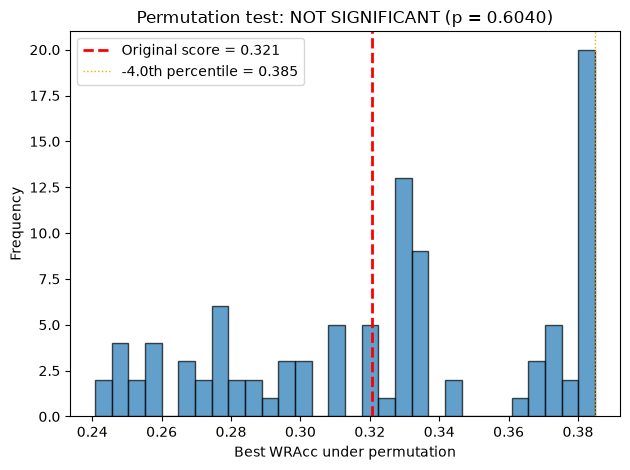

In [7]:
G[2][4]['weight'] = 1

significance_test(G, lu, 'target', 0.320750, 100)